In [ ]:
# ============================================================
# 0. IMPORTS
# ============================================================

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

from xgboost import XGBClassifier

# Optional SMOTE
from imblearn.over_sampling import SMOTE


warnings.filterwarnings("ignore")

sns.set_style("darkgrid")

In [ ]:
# ============================================================
# 1. LOAD DATA
# ============================================================

FILE_PATH = "default of credit card clients.xls"

df = pd.read_csv(FILE_PATH, header=1)

In [ ]:
# ============================================================
# 2. BASIC DATASET INFORMATION
# ============================================================

print("\n========== FIRST 5 ROWS ==========")
print(df.head())

print("\n========== SHAPE ==========")
print(df.shape)

print("\n========== COLUMNS ==========")
print(df.columns.tolist())

print("\n========== INFO ==========")
df.info()

print("\n========== DESCRIPTIVE STATISTICS ==========")
print(df.describe(include="all").T)


========== FIRST 5 ROWS ==========
   ID  LIMIT_BAL  SEX  EDUCATION  MARRIAGE  AGE  PAY_0  PAY_2  PAY_3  PAY_4  \
0   1      20000    2          2         1   24      2      2     -1     -1   
1   2     120000    2          2         2   26     -1      2      0      0   
2   3      90000    2          2         2   34      0      0      0      0   
3   4      50000    2          2         1   37      0      0      0      0   
4   5      50000    1          2         1   57     -1      0     -1      0   

   ...  BILL_AMT4  BILL_AMT5  BILL_AMT6  PAY_AMT1  PAY_AMT2  PAY_AMT3  \
0  ...          0          0          0         0       689         0   
1  ...       3272       3455       3261         0      1000      1000   
2  ...      14331      14948      15549      1518      1500      1000   
3  ...      28314      28959      29547      2000      2019      1200   
4  ...      20940      19146      19131      2000     36681     10000   

   PAY_AMT4  PAY_AMT5  PAY_AMT6  default payment n

In [ ]:
# ============================================================
# 3. DEFINE TARGET AND COLUMN GROUPS
# ============================================================

TARGET = "default payment next month"

ID_COLUMNS = ["ID"]

CATEGORICAL_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE"]

ORDINAL_COLUMNS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

CONTINUOUS_COLUMNS = [
    "LIMIT_BAL",
    "AGE",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6",
]

========== TARGET DISTRIBUTION ==========
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


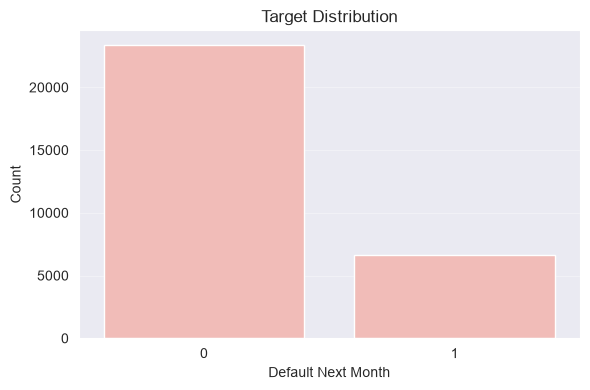

In [ ]:
# ============================================================
# 4. TARGET DISTRIBUTION
# ============================================================

print("\n========== TARGET DISTRIBUTION ==========")

target_counts = df[TARGET].value_counts()

target_percentages = df[TARGET].value_counts(normalize=True) * 100

print(target_counts)

print("\nPercentages:")
print(target_percentages.round(2))


plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=TARGET)

plt.title("Target Distribution")
plt.xlabel("Default Next Month")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 5. MISSING VALUES
# ============================================================

print("\n========== MISSING VALUES ==========")

missing_report = pd.DataFrame(
    {
        "missing_count": df.isnull().sum(),
        "missing_percentage": (df.isnull().mean() * 100).round(2),
    }
)

missing_report = missing_report[missing_report["missing_count"] > 0].sort_values(
    "missing_percentage", ascending=False
)

if missing_report.empty:
    print("No missing values found.")
else:
    print(missing_report)


========== MISSING VALUES ==========
No missing values found.



In [ ]:
# ============================================================
# 6. DUPLICATES
# ============================================================

print("\n========== DUPLICATES ==========")

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

========== DUPLICATES ==========
Duplicate rows: 0



In [ ]:
# ============================================================
# 7. CATEGORICAL / ORDINAL VALUES
# ============================================================

print("\n========== CATEGORY VALUES ==========")

for column in CATEGORICAL_COLUMNS + ORDINAL_COLUMNS:
    print(f"\n--- {column} ---")

    print(df[column].value_counts(dropna=False).sort_index())

========== CATEGORY VALUES ==========

--- SEX ---
SEX
1    11888
2    18112
Name: count, dtype: int64

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

--- PAY_0 ---
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

--- PAY_2 ---
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

--- PAY_3 ---
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

--- PAY_4 ---
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7

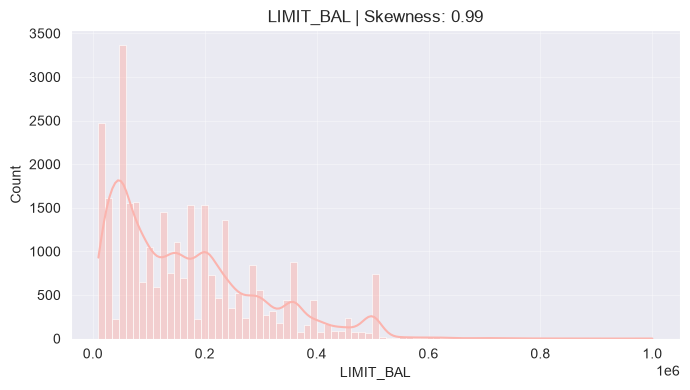

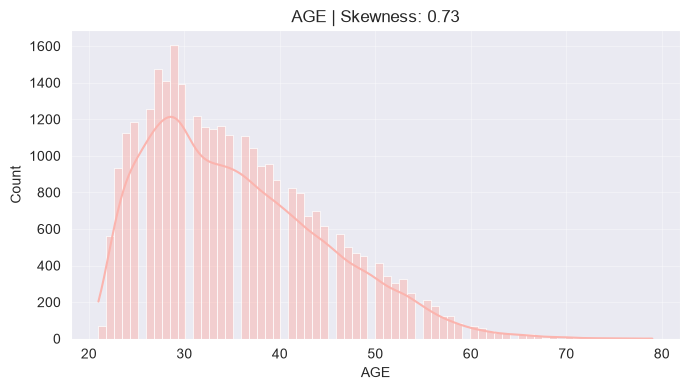

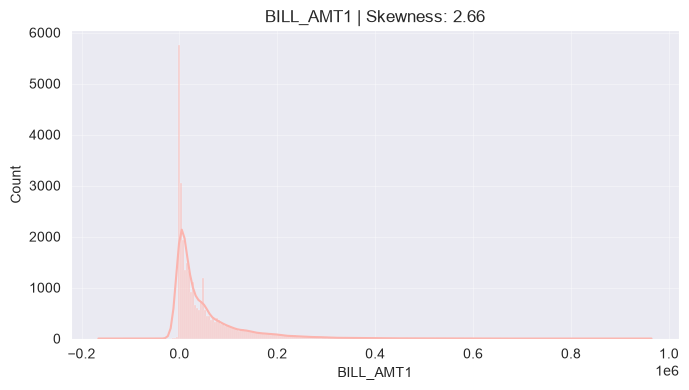

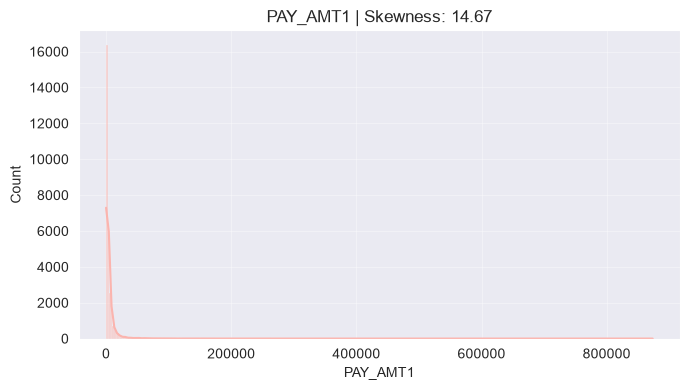

In [ ]:
# ============================================================
# 8. NUMERIC DISTRIBUTIONS
# ============================================================

important_continuous = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]

for column in important_continuous:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=column, kde=True)

    plt.title(f"{column} | Skewness: {df[column].skew():.2f}")

    plt.tight_layout()
    plt.show()

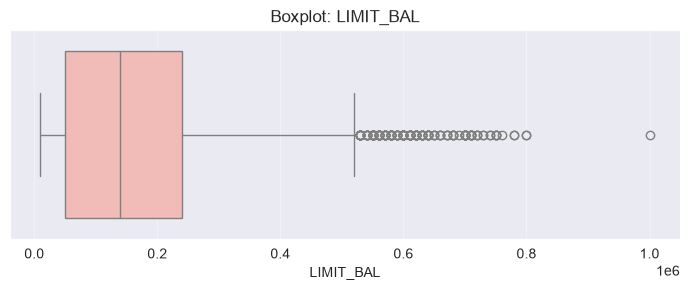

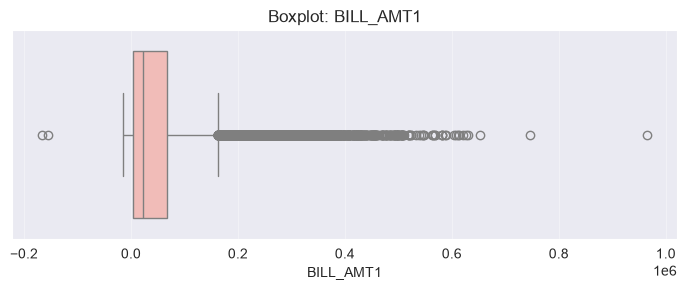

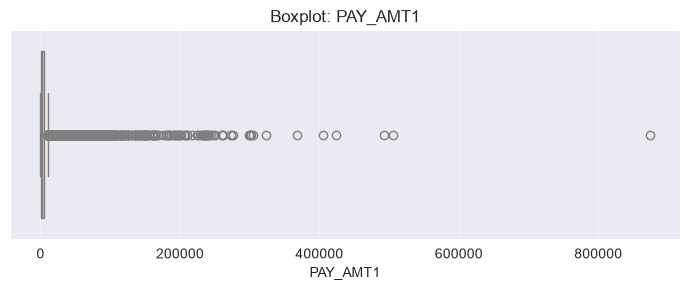

In [ ]:
# ============================================================
# 9. BOXPLOTS
# ============================================================

for column in ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]:
    plt.figure(figsize=(7, 3))

    sns.boxplot(x=df[column])

    plt.title(f"Boxplot: {column}")

    plt.tight_layout()
    plt.show()

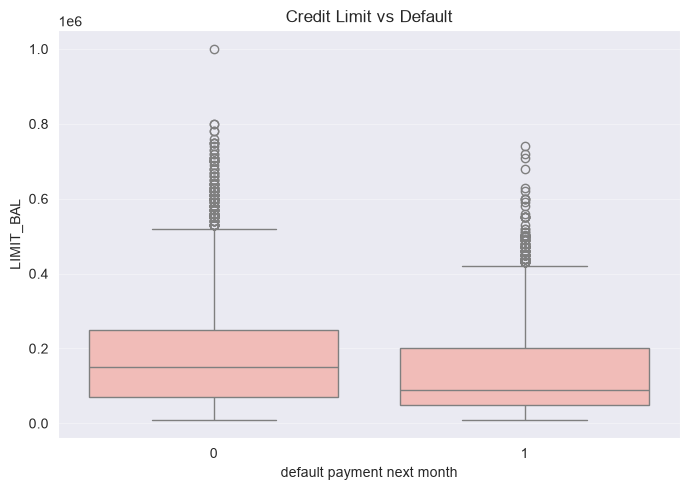

In [ ]:
# ============================================================
# 10. NUMERIC FEATURE VS TARGET
# ============================================================

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x=TARGET, y="LIMIT_BAL")

plt.title("Credit Limit vs Default")

plt.tight_layout()
plt.show()

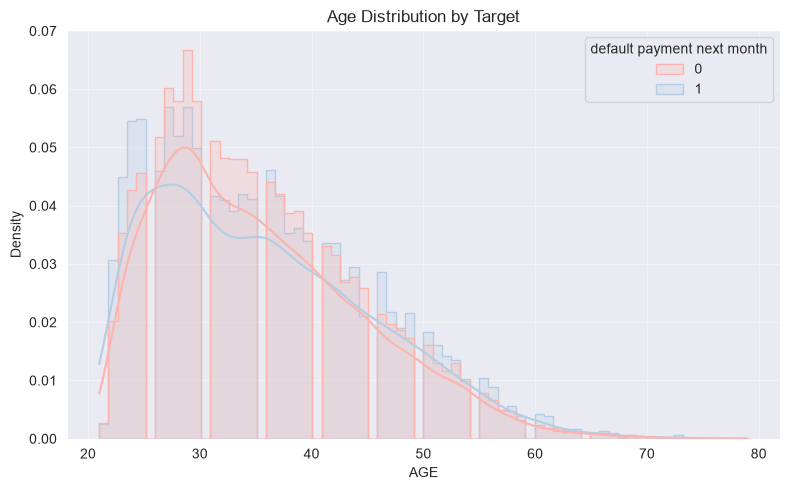

In [ ]:
# ============================================================
# 11. NUMERIC DISTRIBUTION BY TARGET
# ============================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="AGE",
    hue=TARGET,
    kde=True,
    element="step",
    stat="density",
    common_norm=False,
)

plt.title("Age Distribution by Target")

plt.tight_layout()
plt.show()

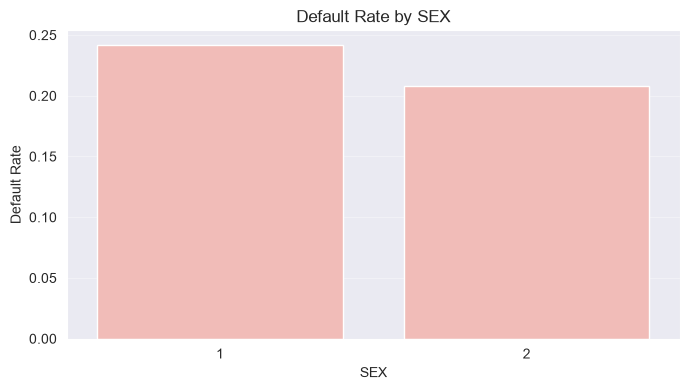

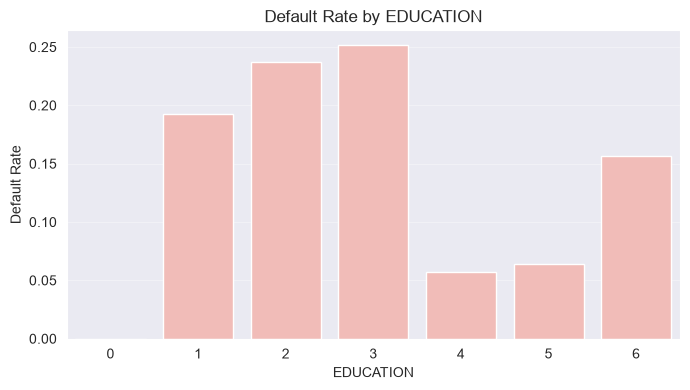

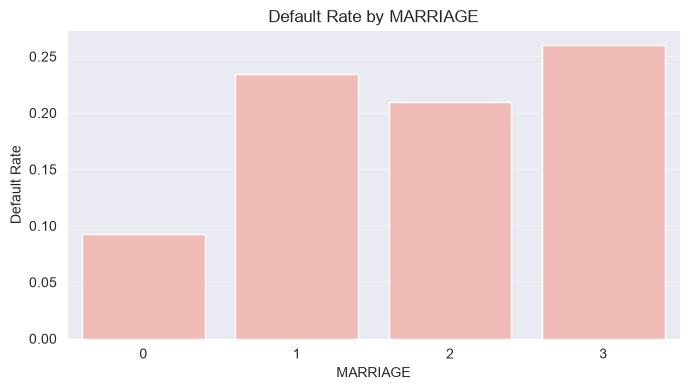

In [ ]:
# ============================================================
# 12. CATEGORICAL FEATURE VS TARGET
# ============================================================

for column in CATEGORICAL_COLUMNS:
    default_rate = df.groupby(column)[TARGET].mean().reset_index()

    plt.figure(figsize=(7, 4))

    sns.barplot(data=default_rate, x=column, y=TARGET)

    plt.title(f"Default Rate by {column}")
    plt.ylabel("Default Rate")

    plt.tight_layout()
    plt.show()

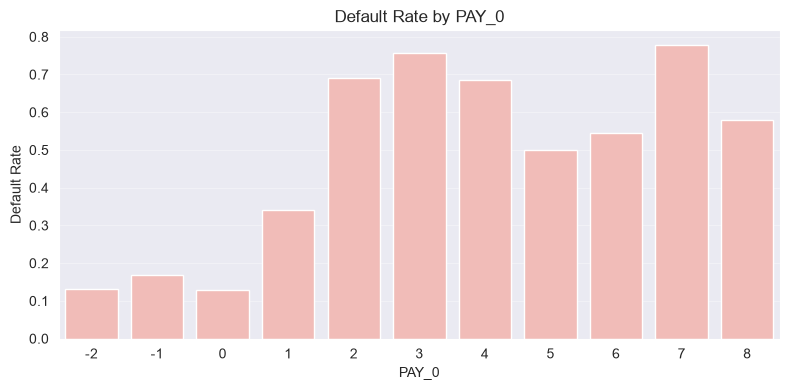

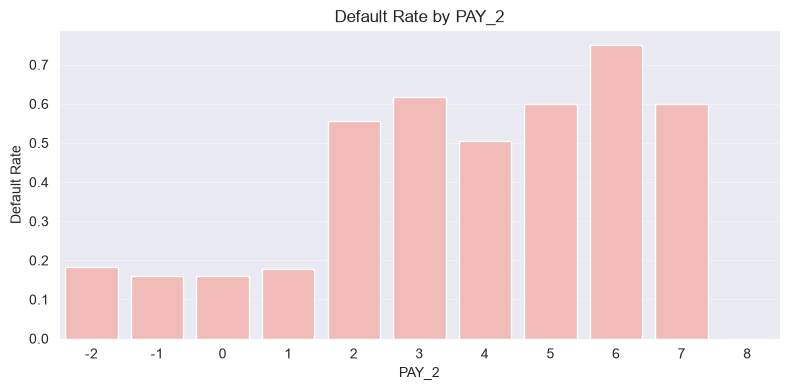

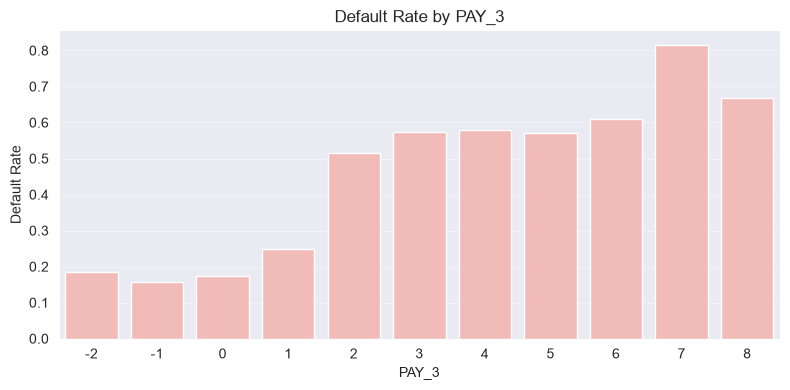

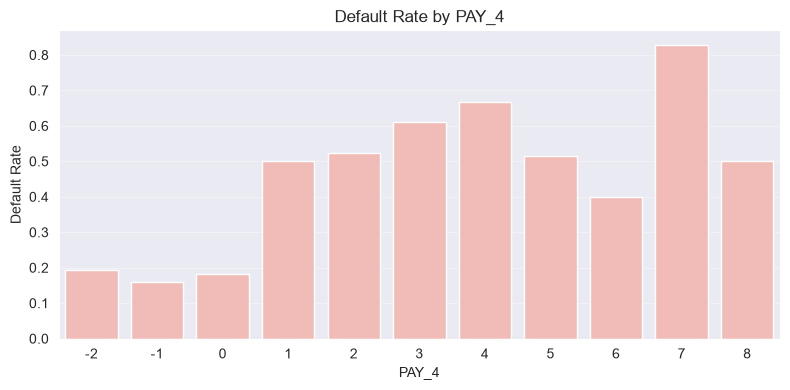

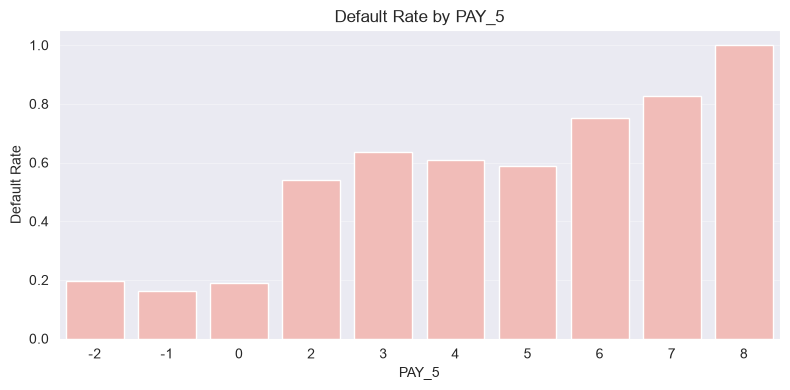

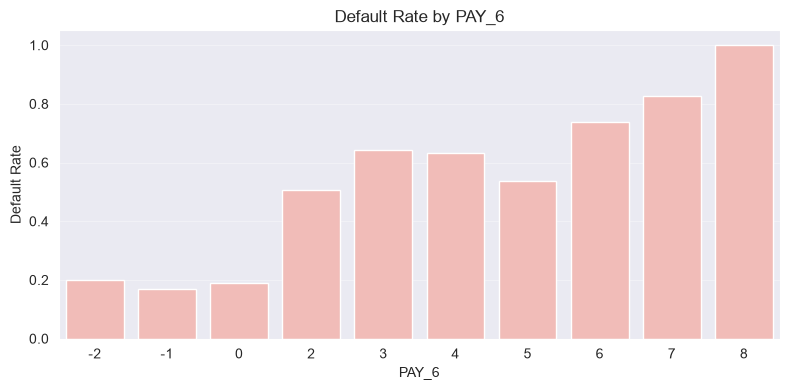

In [ ]:
# ============================================================
# 13. ORDINAL FEATURE VS TARGET
# ============================================================

for column in ORDINAL_COLUMNS:
    default_rate = df.groupby(column)[TARGET].mean().reset_index()

    plt.figure(figsize=(8, 4))

    sns.barplot(data=default_rate, x=column, y=TARGET)

    plt.title(f"Default Rate by {column}")
    plt.ylabel("Default Rate")

    plt.tight_layout()
    plt.show()

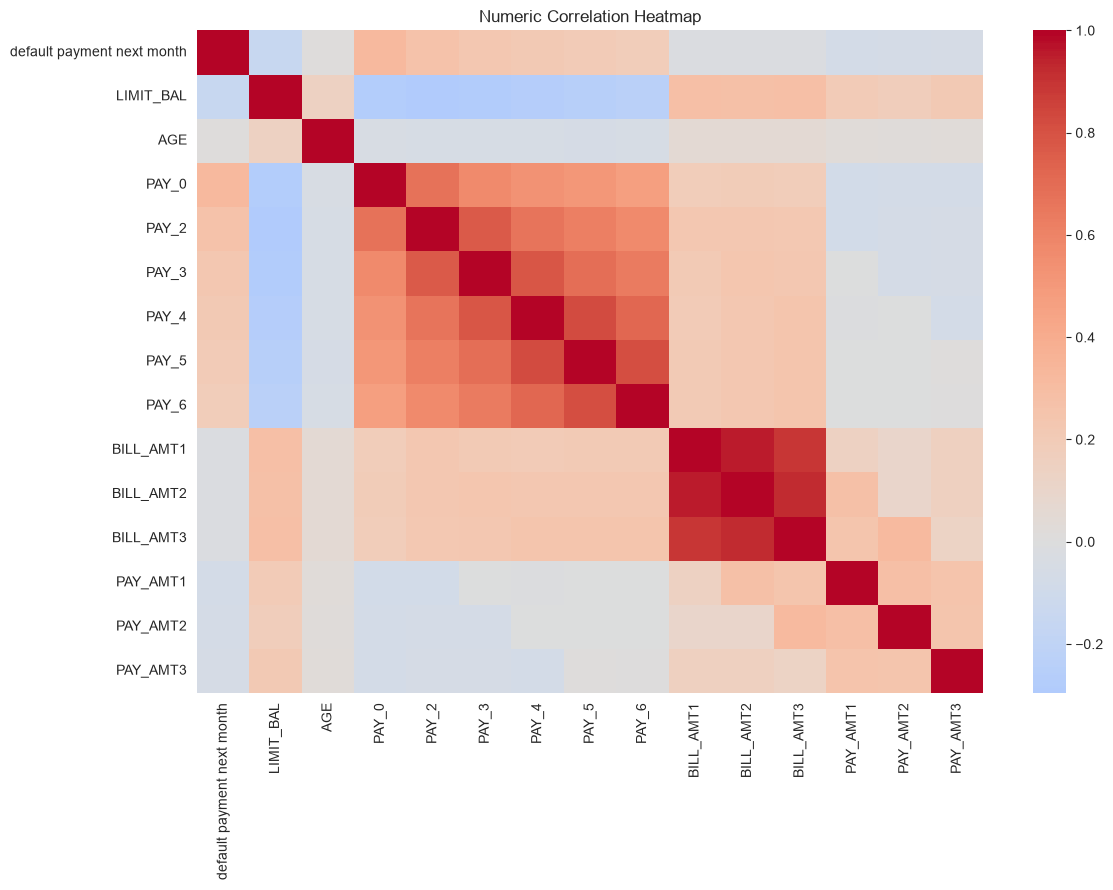

In [ ]:
# ============================================================
# 14. NUMERIC CORRELATION
# ============================================================

correlation_columns = [
    TARGET,
    "LIMIT_BAL",
    "AGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
]

corr_matrix = df[correlation_columns].corr()


plt.figure(figsize=(12, 9))

sns.heatmap(corr_matrix, cmap="coolwarm", center=0)

plt.title("Numeric Correlation Heatmap")

plt.tight_layout()
plt.show()

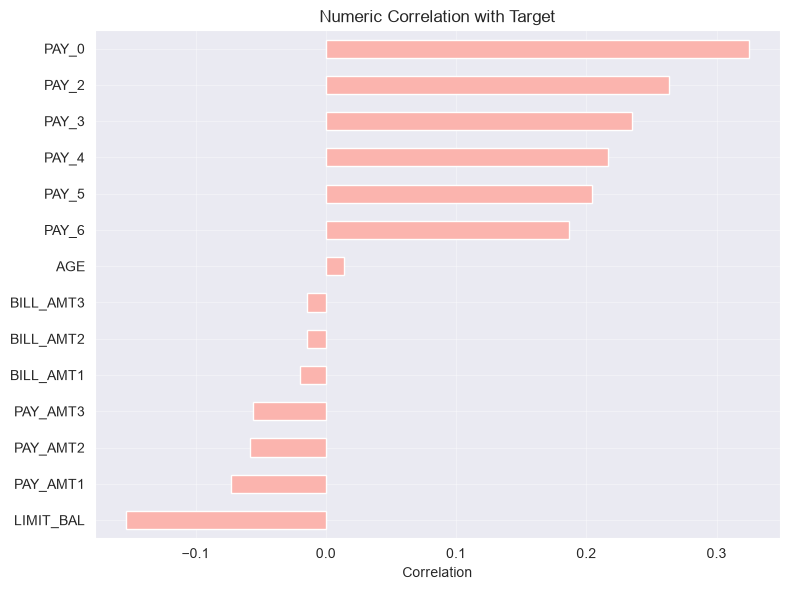

In [ ]:
# ============================================================
# 15. CORRELATION WITH TARGET
# ============================================================

target_corr = corr_matrix[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(8, 6))

target_corr.plot(kind="barh")

plt.title("Numeric Correlation with Target")
plt.xlabel("Correlation")

plt.tight_layout()
plt.show()

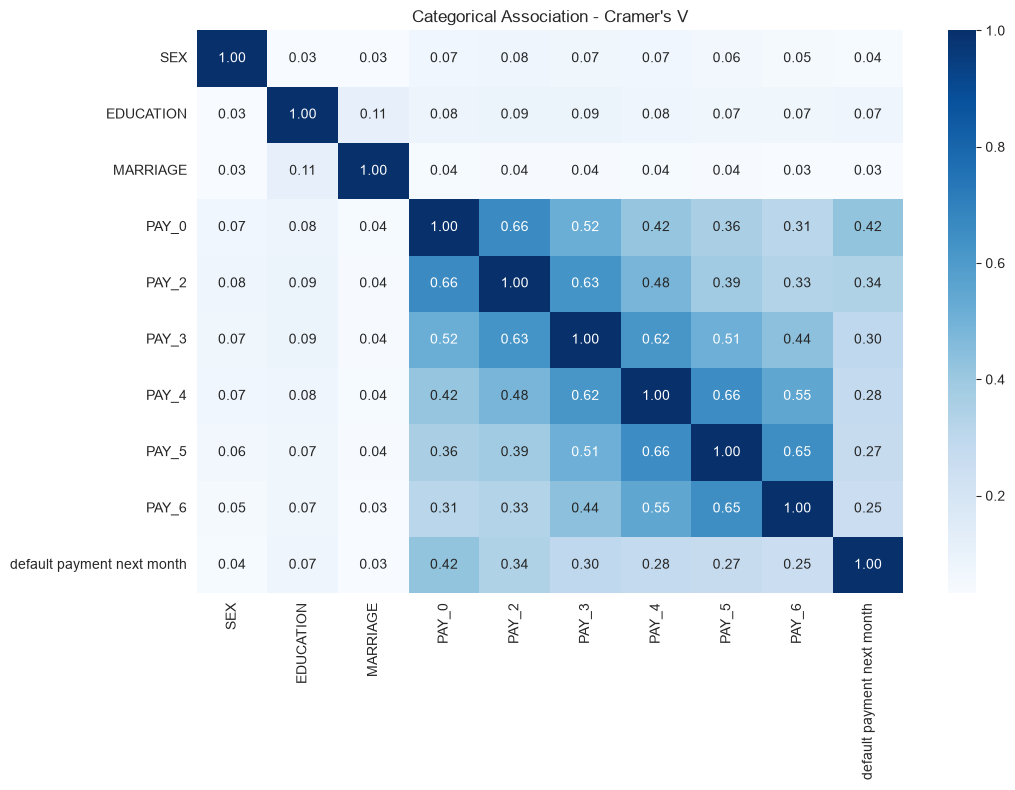

In [ ]:
# ============================================================
# 16. CATEGORICAL ASSOCIATION - CRAMER'S V
# ============================================================


def cramers_v(x, y):

    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(table)[0]

    n = table.sum().sum()

    rows, cols = table.shape

    denominator = min(rows - 1, cols - 1)

    if denominator == 0:
        return 0

    return np.sqrt((chi2 / n) / denominator)


categorical_for_analysis = CATEGORICAL_COLUMNS + ORDINAL_COLUMNS + [TARGET]

cramers_matrix = pd.DataFrame(
    index=categorical_for_analysis, columns=categorical_for_analysis, dtype=float
)

for col1 in categorical_for_analysis:
    for col2 in categorical_for_analysis:
        cramers_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])


plt.figure(figsize=(11, 8))

sns.heatmap(cramers_matrix, annot=True, fmt=".2f", cmap="Blues")

plt.title("Categorical Association - Cramer's V")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 17. DATA QUALITY SUMMARY
# ============================================================

print("\n========== EDA SUMMARY ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Duplicates:", duplicate_count)

print("Positive class rate:", round(df[TARGET].mean() * 100, 2), "%")

print("Columns with missing values:", (df.isnull().sum() > 0).sum())


========== EDA SUMMARY ==========
Rows: 30000
Columns: 25
Duplicates: 0
Positive class rate: 22.12 %
Columns with missing values: 0



In [ ]:
# ============================================================
# 18. FEATURES AND TARGET
# ============================================================

X = df.drop(columns=[TARGET] + ID_COLUMNS)

y = df[TARGET]

In [ ]:
# ============================================================
# 19. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)


print("\n========== SPLIT SHAPES ==========")

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

========== SPLIT SHAPES ==========
Train: (21000, 23)
Validation: (4500, 23)
Test: (4500, 23)



In [ ]:
# ============================================================
# 20. NUMERIC PREPROCESSING
# ============================================================

numeric_pipeline = Pipeline(
    [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

In [ ]:
# ============================================================
# 21. CATEGORICAL PREPROCESSING
# ============================================================

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [ ]:
# ============================================================
# 22. ORDINAL PREPROCESSING
# ============================================================

ordinal_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])

In [ ]:
# ============================================================
# 23. COMBINE PREPROCESSING
# ============================================================

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, CONTINUOUS_COLUMNS),
        ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS),
        ("ordinal", ordinal_pipeline, ORDINAL_COLUMNS),
    ]
)

In [ ]:
# ============================================================
# 24. FIT PREPROCESSING
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)


print("\n========== PROCESSED SHAPES ==========")

print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

========== PROCESSED SHAPES ==========
Train: (21000, 33)
Validation: (4500, 33)
Test: (4500, 33)



In [ ]:
# ============================================================
# 25. CLASS IMBALANCE INFORMATION
# ============================================================

negative_count = (y_train == 0).sum()

positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count


print("\n========== CLASS BALANCE ==========")

print("Negative:", negative_count)
print("Positive:", positive_count)

print("XGBoost scale_pos_weight:", round(scale_pos_weight, 2))

========== CLASS BALANCE ==========
Negative: 16355
Positive: 4645
XGBoost scale_pos_weight: 3.52



In [ ]:
# ============================================================
# 26. MODEL 1 - LOGISTIC REGRESSION
# ============================================================

logistic_model = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=42
)

logistic_model.fit(X_train_processed, y_train)

In [ ]:
# ============================================================
# 27. MODEL 2 - RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

In [ ]:
# ============================================================
# 28. MODEL 3 - XGBOOST
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train_processed, y_train)

In [ ]:
# ============================================================
# 29. OPTIONAL SMOTE
# ============================================================

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)


print("\n========== AFTER SMOTE ==========")

print(pd.Series(y_train_smote).value_counts())

========== AFTER SMOTE ==========
default payment next month
0    16355
1    16355
Name: count, dtype: int64



In [ ]:
# ============================================================
# 30. LOGISTIC REGRESSION WITH SMOTE
# ============================================================

logistic_smote_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_smote_model.fit(X_train_smote, y_train_smote)

In [ ]:
# ============================================================
# 31. EVALUATION FUNCTION
# ============================================================


def evaluate_model(model, X, y, model_name, threshold=0.5):

    probabilities = model.predict_proba(X)[:, 1]

    predictions = (probabilities >= threshold).astype(int)

    accuracy = accuracy_score(y, predictions)

    precision = precision_score(y, predictions, zero_division=0)

    recall = recall_score(y, predictions, zero_division=0)

    f1 = f1_score(y, predictions, zero_division=0)

    roc_auc = roc_auc_score(y, probabilities)

    pr_auc = average_precision_score(y, probabilities)

    print(f"\n========== {model_name} ==========")

    print(f"Threshold : {threshold:.2f}")
    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1        : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")
    print(f"PR-AUC    : {pr_auc:.4f}")

    print("\nClassification Report:")

    print(classification_report(y, predictions, zero_division=0))

    print("\nConfusion Matrix:")

    print(confusion_matrix(y, predictions))

    return {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
    }

In [ ]:
# ============================================================
# 32. VALIDATION EVALUATION
# ============================================================

logistic_results = evaluate_model(
    logistic_model, X_val_processed, y_val, "Logistic Regression"
)

rf_results = evaluate_model(rf_model, X_val_processed, y_val, "Random Forest")

xgb_results = evaluate_model(xgb_model, X_val_processed, y_val, "XGBoost")

smote_results = evaluate_model(
    logistic_smote_model, X_val_processed, y_val, "Logistic Regression + SMOTE"
)

========== Logistic Regression ==========
Threshold : 0.50
Accuracy  : 0.6811
Precision : 0.3709
Recall    : 0.6352
F1        : 0.4683
ROC-AUC   : 0.7148
PR-AUC    : 0.5002

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.69      0.77      3505
           1       0.37      0.64      0.47       995

    accuracy                           0.68      4500
   macro avg       0.62      0.66      0.62      4500
weighted avg       0.76      0.68      0.71      4500


Confusion Matrix:
[[2433 1072]
 [ 363  632]]

========== Random Forest ==========
Threshold : 0.50
Accuracy  : 0.7769
Precision : 0.4961
Recall    : 0.5819
F1        : 0.5356
ROC-AUC   : 0.7763
PR-AUC    : 0.5511

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85      3505
           1       0.50      0.58      0.54       995

    accuracy                           0.78      4500
   macro avg       0

In [ ]:
# ============================================================
# 33. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame([logistic_results, rf_results, xgb_results, smote_results])

results_df = results_df.sort_values("pr_auc", ascending=False)

print("\n========== MODEL COMPARISON ==========")

print(results_df)

========== MODEL COMPARISON ==========
                         model  accuracy  precision    recall        f1  \
1                Random Forest  0.776889   0.496144  0.581910  0.535615   
2                      XGBoost  0.763778   0.473101  0.601005  0.529438   
3  Logistic Regression + SMOTE  0.665778   0.356781  0.637186  0.457431   
0          Logistic Regression  0.681111   0.370892  0.635176  0.468322   

    roc_auc    pr_auc  
1  0.776339  0.551142  
2  0.773131  0.545529  
3  0.716316  0.501405  
0  0.714807  0.500182  


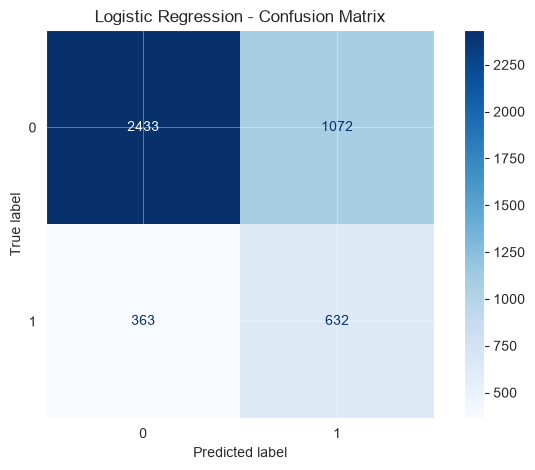

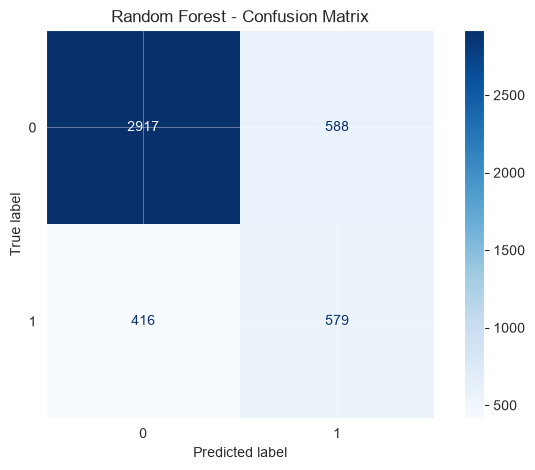

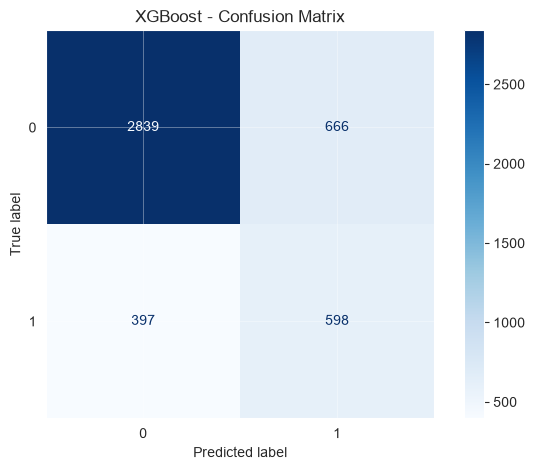

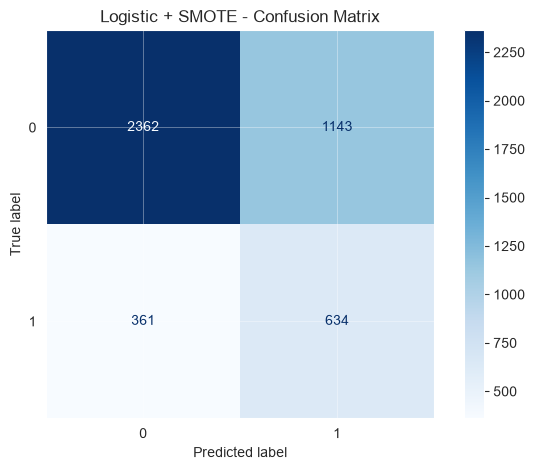

In [ ]:
# ============================================================
# 34. CONFUSION MATRIX PLOTS
# ============================================================

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "Logistic + SMOTE": logistic_smote_model,
}

for name, model in models.items():
    ConfusionMatrixDisplay.from_estimator(model, X_val_processed, y_val, cmap="Blues")

    plt.title(f"{name} - Confusion Matrix")

    plt.tight_layout()
    plt.show()

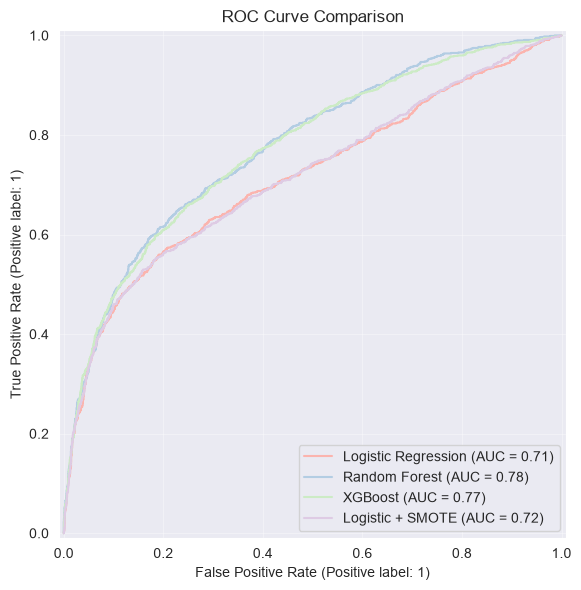

In [ ]:
# ============================================================
# 35. ROC CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_val_processed, y_val, name=name, ax=ax)

plt.title("ROC Curve Comparison")

plt.tight_layout()
plt.show()

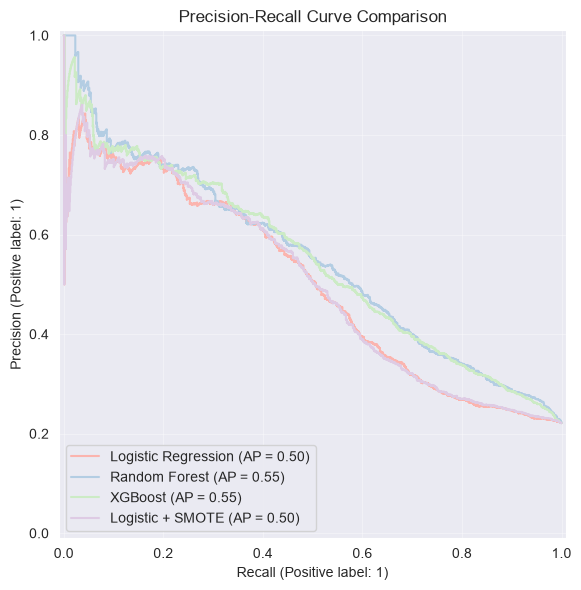

In [ ]:
# ============================================================
# 36. PRECISION-RECALL CURVES
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(
        model, X_val_processed, y_val, name=name, ax=ax
    )

plt.title("Precision-Recall Curve Comparison")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 37. THRESHOLD TUNING
# ============================================================

best_model = xgb_model

probabilities = best_model.predict_proba(X_val_processed)[:, 1]


threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (probabilities >= threshold).astype(int)

    precision = precision_score(y_val, predictions, zero_division=0)

    recall = recall_score(y_val, predictions, zero_division=0)

    f1 = f1_score(y_val, predictions, zero_division=0)

    threshold_results.append(
        {"threshold": threshold, "precision": precision, "recall": recall, "f1": f1}
    )


threshold_df = pd.DataFrame(threshold_results)


print("\n========== THRESHOLD RESULTS ==========")

print(threshold_df)


========== THRESHOLD RESULTS ==========
    threshold  precision    recall        f1
0        0.10   0.229638  0.988945  0.372727
1        0.15   0.246942  0.973869  0.393983
2        0.20   0.265683  0.940704  0.414343
3        0.25   0.286774  0.893467  0.434188
4        0.30   0.316323  0.847236  0.460656
5        0.35   0.348492  0.777889  0.481343
6        0.40   0.388489  0.705528  0.501071
7        0.45   0.433177  0.648241  0.519324
8        0.50   0.473101  0.601005  0.529438
9        0.55   0.505587  0.545729  0.524891
10       0.60   0.551991  0.501508  0.525540
11       0.65   0.586873  0.458291  0.514673
12       0.70   0.627481  0.413065  0.498182
13       0.75   0.645683  0.360804  0.462927
14       0.80   0.683761  0.321608  0.437457
15       0.85   0.704188  0.270352  0.390704
16       0.90   0.754808  0.157789  0.261014


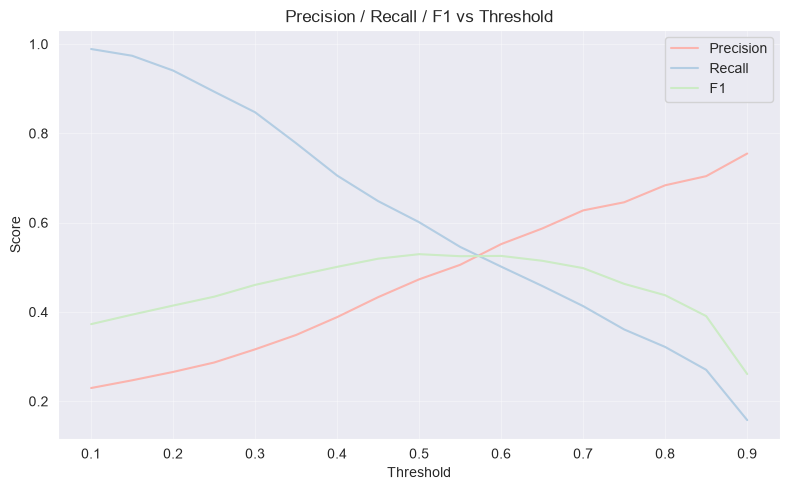

In [ ]:
# ============================================================
# 38. THRESHOLD PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")

plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")

plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")

plt.xlabel("Threshold")
plt.ylabel("Score")

plt.title("Precision / Recall / F1 vs Threshold")

plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 39. SELECT BEST THRESHOLD BY F1
# ============================================================

best_threshold_row = threshold_df.loc[threshold_df["f1"].idxmax()]

best_threshold = best_threshold_row["threshold"]


print("\nBest validation threshold:", round(best_threshold, 2))


Best validation threshold: 0.5



In [ ]:
# ============================================================
# 40. FINAL TEST EVALUATION
# ============================================================

final_results = evaluate_model(
    best_model, X_test_processed, y_test, "Final XGBoost Test", threshold=best_threshold
)

========== Final XGBoost Test ==========
Threshold : 0.50
Accuracy  : 0.7696
Precision : 0.4839
Recall    : 0.6185
F1        : 0.5430
ROC-AUC   : 0.7783
PR-AUC    : 0.5581

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.85      3504
           1       0.48      0.62      0.54       996

    accuracy                           0.77      4500
   macro avg       0.68      0.72      0.69      4500
weighted avg       0.79      0.77      0.78      4500


Confusion Matrix:
[[2847  657]
 [ 380  616]]



In [ ]:
# ============================================================
# 41. FINAL SUMMARY
# ============================================================

print("\n========== FINAL RESULT ==========")

print("Selected model:", "XGBoost")

print("Selected threshold:", round(best_threshold, 2))

print("Test PR-AUC:", round(final_results["pr_auc"], 4))

print("Test F1:", round(final_results["f1"], 4))

========== FINAL RESULT ==========
Selected model: XGBoost
Selected threshold: 0.5
Test PR-AUC: 0.5581
Test F1: 0.543
